<a href="https://colab.research.google.com/github/auyashas/fake-job-posting-analyzer/blob/main/fakeJobPostAnalyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Dataset Identification

**Project Title:** Machine Learning Based Detection of Fraudulent Job Postings

**Dataset Name:** Real or Fake Job Posting Prediction (Employment Scam Aegean Dataset — EMSCAD)

**Dataset Source:** [Kaggle — Real or Fake Job Posting Prediction](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction)

**Dataset Size:** 17,880 job postings and 18 columns.

**Target Variable:** `fraudulent`

- `0` — Legitimate job posting
- `1` — Fraudulent job posting

**Problem Type:** Supervised binary classification.

**Data Type:** A combination of textual, categorical, binary, and identifier data.

**Dataset Description:** The dataset contains job advertisements with information such as job titles, descriptions, company profiles, qualifications, benefits, employment types, and other job-related attributes. It can be used to develop machine learning models that classify job postings as legitimate or fraudulent.

# 2. Dataset Metadata


In [ ]:
metadata = [
    ("job_id", "Identifier", "Unique identifier for a job posting"),
    ("title", "Text", "Title of the advertised job"),
    ("location", "Text/Categorical", "Geographical location of the job"),
    ("department", "Categorical", "Department offering the job"),
    ("salary_range", "Text", "Advertised salary range"),
    ("company_profile", "Text", "Information about the company"),
    ("description", "Text", "Description of the job and responsibilities"),
    ("requirements", "Text", "Required skills and qualifications"),
    ("benefits", "Text", "Benefits offered to employees"),
    ("telecommuting", "Binary", "Whether remote work is allowed"),
    ("has_company_logo", "Binary", "Whether a company logo is present"),
    ("has_questions", "Binary", "Whether screening questions are included"),
    ("employment_type", "Categorical", "Type of employment"),
    ("required_experience", "Categorical", "Required experience level"),
    ("required_education", "Categorical", "Required education level"),
    ("industry", "Categorical", "Industry associated with the job"),
    ("function", "Categorical", "Job function or occupational area"),
    ("fraudulent", "Target/Binary", "0 = legitimate, 1 = fraudulent"),
]

metadata_df = pd.DataFrame(
    metadata,
    columns=["Column", "Data Type", "Description"]
)

display(metadata_df)

,Column,Data Type,Description
0,job_id,Identifier,Unique identifier for a job posting
1,title,Text,Title of the advertised job
2,location,Text/Categorical,Geographical location of the job
3,department,Categorical,Department offering the job
4,salary_range,Text,Advertised salary range
5,company_profile,Text,Information about the company
6,description,Text,Description of the job and responsibilities
7,requirements,Text,Required skills and qualifications
8,benefits,Text,Benefits offered to employees
9,telecommuting,Binary,Whether remote work is allowed


# 3. Problem Statement

Online job platforms can contain fraudulent job advertisements intended to mislead job seekers. Identifying such advertisements manually can be time-consuming and difficult because legitimate and fraudulent postings may share similar characteristics.

This project aims to develop a machine learning-based classification system that analyzes textual and structured information from job advertisements to predict whether a posting is legitimate or fraudulent.


# 4. Project Objectives

1. Explore the dataset to understand its structure, feature distributions, missing values, and class imbalance.
2. Identify characteristics that may help distinguish legitimate job postings from fraudulent ones.
3. Develop a preprocessing pipeline suitable for textual and structured job advertisement data.
4. Shortlist appropriate machine learning algorithms, including ensemble learning methods.
5. Evaluate candidate models using suitable classification metrics, particularly precision, recall, F1-score, and the confusion matrix.
6. Identify a suitable model for fraudulent job posting detection based on experimental results.

# 5. Dataset Loading

The dataset is loaded into a Pandas DataFrame for further inspection and exploratory data analysis. Pandas is used to read and manipulate the CSV data.

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/fake_job_postings.csv",
    encoding="utf-8"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/content/fake_job_postings.csv'

# 6. Initial Dataset Inspection

Initial inspection is performed to understand the structure, dimensions, data types, missing values, and duplicate records in the dataset before conducting detailed exploratory data analysis.

In [ ]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# First five records
print("\nFirst five records:")
display(df.head())

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics of the dataset, identify patterns, examine missing values, and investigate differences between legitimate and fraudulent job postings. Graphs and summary statistics are used to identify patterns that may be useful for machine learning.

## 7.1 Target Variable Distribution

The target variable `fraudulent` indicates whether a job posting is legitimate or fraudulent. The class distribution is examined to understand the balance between the two categories.

Class counts:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Class percentages:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


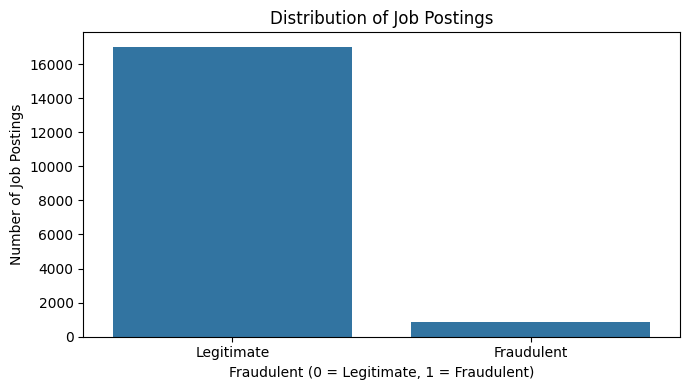

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

target_counts = df["fraudulent"].value_counts().sort_index()

print("Class counts:")
print(target_counts)

print("\nClass percentages:")
print(
    (df["fraudulent"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="fraudulent")

plt.title("Distribution of Job Postings")
plt.xlabel("Fraudulent (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Number of Job Postings")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.tight_layout()
plt.show()

**Observation:** The dataset contains 17,014 legitimate job postings (95.16%) and 866 fraudulent job postings (4.84%). This indicates a substantial class imbalance. Therefore, accuracy alone may not adequately represent model performance, and precision, recall, F1-score, and the confusion matrix should be considered during evaluation.

## 7.2 Missing-Value Analysis

Missing values are examined to identify columns with incomplete information. Understanding the extent of missing data helps determine suitable preprocessing methods.

,Missing Count,Missing Percentage
salary_range,15012,83.96
department,11547,64.58
required_education,8105,45.33
benefits,7212,40.34
required_experience,7050,39.43
function,6455,36.10
industry,4903,27.42
employment_type,3471,19.41
company_profile,3308,18.50
requirements,2696,15.08


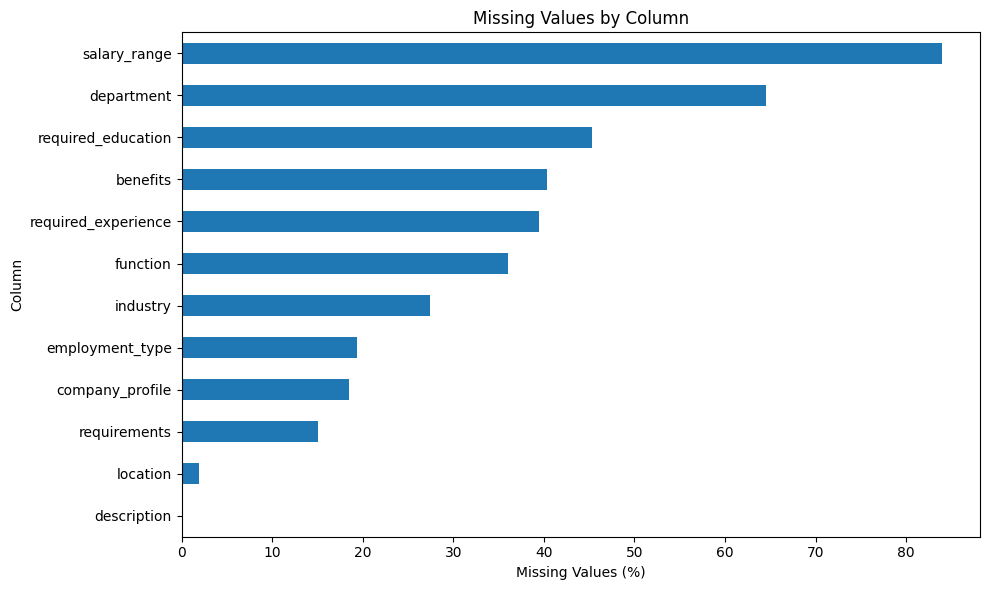

In [ ]:
missing_count = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": (
        missing_count / len(df) * 100
    ).round(2)
})

missing_df = missing_df[
    missing_df["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_df)

plt.figure(figsize=(10, 6))

missing_df["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

**Observation:** The missing-value analysis shows that `salary_range` has the highest proportion of missing values (83.96%), followed by `department` (64.58%). Other features, including `required_education` (45.33%) and `benefits` (40.34%), also contain substantial missing data. The `description` column has only one missing value (0.01%). These findings indicate that missing values must be handled carefully during preprocessing rather than removing all incomplete records.

## 7.3 Categorical Feature Analysis

The distributions of selected categorical features are examined to identify the most frequently occurring job types, experience levels, education requirements, industries, and job functions.

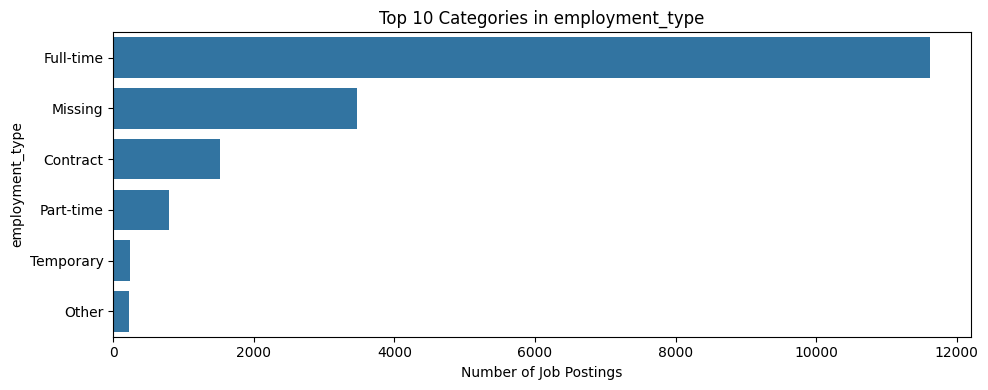

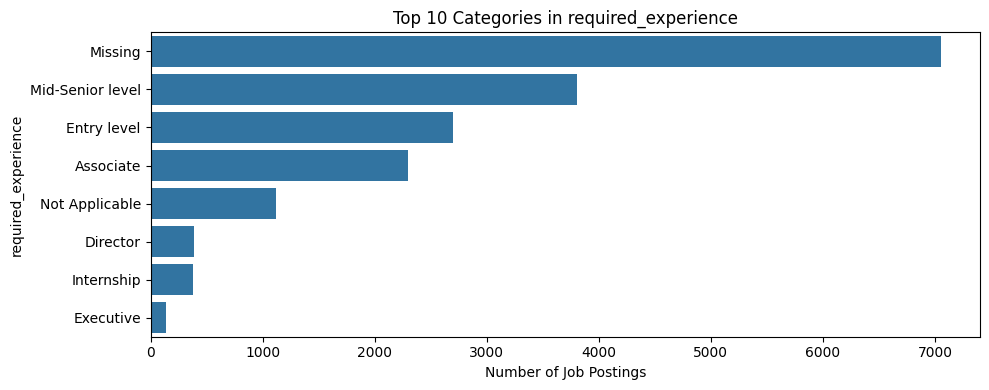

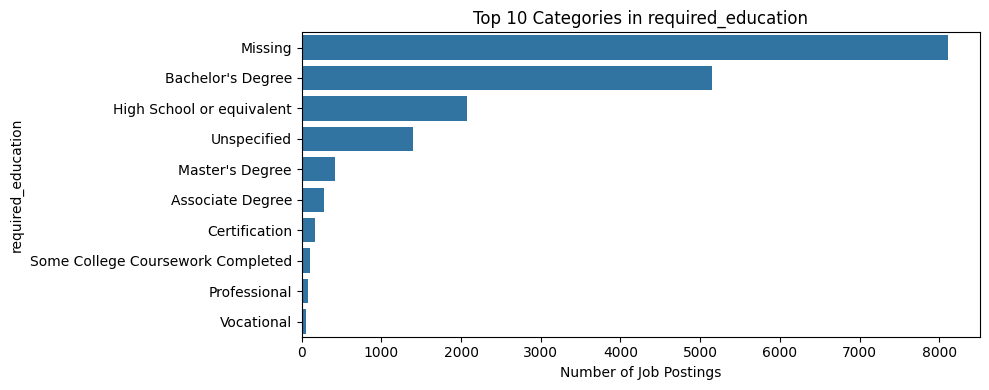

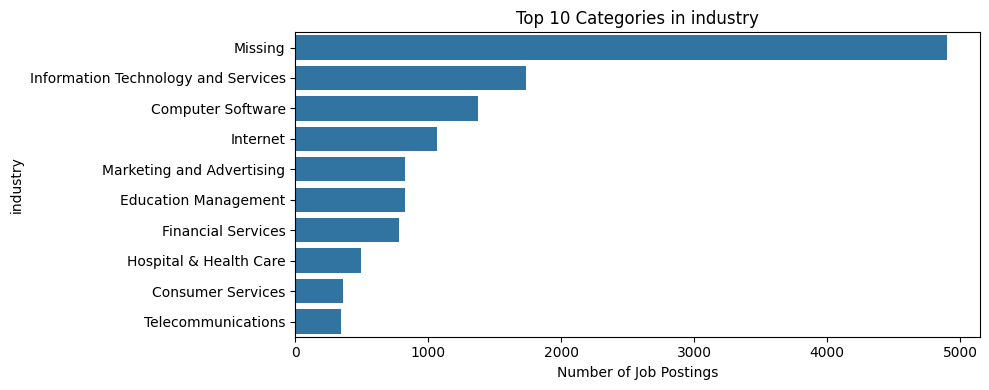

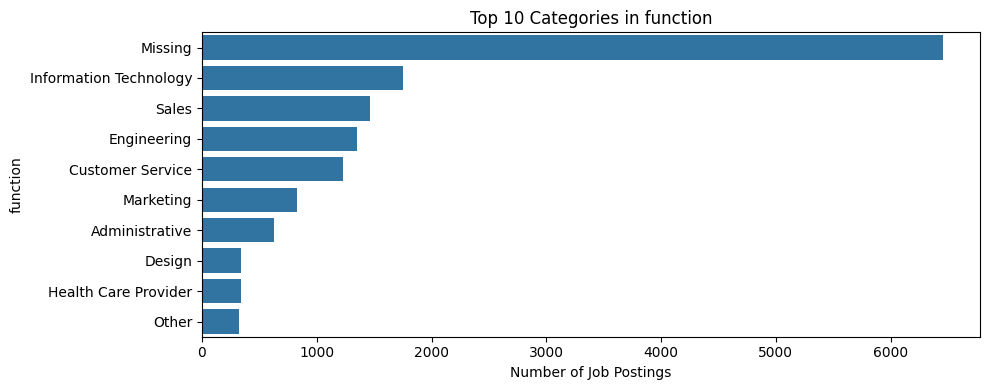

In [ ]:
categorical_cols = [
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

for col in categorical_cols:
    plt.figure(figsize=(10, 4))

    values = (
        df[col]
        .fillna("Missing")
        .value_counts()
        .head(10)
    )

    sns.barplot(x=values.values, y=values.index)

    plt.title(f"Top 10 Categories in {col}")
    plt.xlabel("Number of Job Postings")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

**Observation:** The categorical distributions show how job advertisements are represented across employment types, experience levels, education requirements, industries, and job functions. These features may provide useful information for classification. However, the current charts show category frequencies rather than fraudulent posting rates within each category. Missing categorical values will need to be handled, and categorical features will require appropriate encoding before model training.

## 7.4 Text-Length Analysis

Text-length analysis is used to examine the lengths of job titles, company profiles, descriptions, requirements, and benefits. Comparing text lengths across legitimate and fraudulent postings may reveal useful patterns in the advertisements.

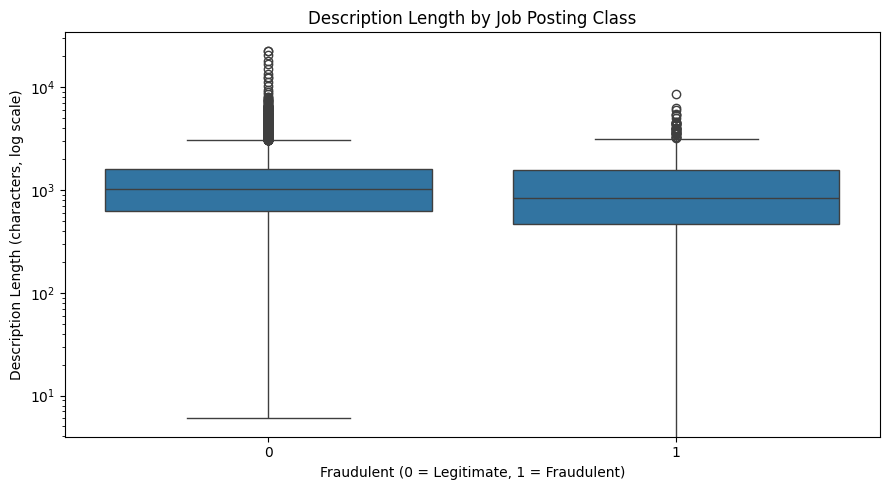

Average text length by class:


,title_length,company_profile_length,description_length,requirements_length,benefits_length
fraudulent,,,,,
0,28.42,646.54,1238.69,603.25,211.22
1,30.67,233.14,1162.70,451.06,214.98


In [ ]:
text_cols = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

text_lengths = pd.DataFrame(index=df.index)

for col in text_cols:
    text_lengths[f"{col}_length"] = (
        df[col].fillna("").str.len()
    )

text_lengths["fraudulent"] = df["fraudulent"]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=text_lengths,
    x="fraudulent",
    y="description_length"
)

plt.yscale("log")
plt.title("Description Length by Job Posting Class")
plt.xlabel("Fraudulent (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Description Length (characters, log scale)")
plt.tight_layout()
plt.show()

print("Average text length by class:")
display(
    text_lengths.groupby("fraudulent")[
        [f"{col}_length" for col in text_cols]
    ].mean().round(2)
)


**Observation:** The boxplot shows that legitimate job postings have a slightly higher median description length than fraudulent postings. The average description length is 1,238.69 characters for legitimate postings and 1,162.70 characters for fraudulent postings. The average company profile and requirements lengths are also higher for legitimate postings, while the average title and benefits lengths are slightly higher for fraudulent postings. These differences may provide useful information for classification; however, text length alone cannot determine whether a job posting is fraudulent.

## 7.5 Binary Feature Analysis

The relationship between selected binary features and fraudulent job postings is examined. These features include telecommuting availability, company logo presence, and the inclusion of screening questions.

In [ ]:
binary_cols = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

for col in binary_cols:
    summary = (
        df.groupby(col, dropna=False)["fraudulent"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Number of Postings",
            "mean": "Fraudulent Rate"
        })
    )

    summary["Fraudulent Rate (%)"] = (
        summary["Fraudulent Rate"] * 100
    ).round(2)

    print(f"\nAnalysis of {col}:")
    display(summary)


Analysis of telecommuting:


,Number of Postings,Fraudulent Rate,Fraudulent Rate (%)
telecommuting,,,
0,17113,0.046865,4.69
1,767,0.083442,8.34



Analysis of has_company_logo:


,Number of Postings,Fraudulent Rate,Fraudulent Rate (%)
has_company_logo,,,
0,3660,0.159290,15.93
1,14220,0.019902,1.99



Analysis of has_questions:


,Number of Postings,Fraudulent Rate,Fraudulent Rate (%)
has_questions,,,
0,9088,0.067782,6.78
1,8792,0.028435,2.84


**Observation:** The fraudulent posting rate is higher among postings without a company logo (15.93%) than among those with a logo (1.99%). Postings without screening questions also show a higher fraudulent rate (6.78%) than those with screening questions (2.84%). Additionally, postings allowing telecommuting have a higher fraudulent rate (8.34%) than postings that do not (4.69%). These patterns indicate potentially useful associations for classification, but they do not establish causation.

# 8. Proposed Preprocessing Pipeline

The dataset contains textual, categorical, binary, and identifier features. A preprocessing pipeline will be designed to transform these features into a suitable representation for machine learning.

1. **Data validation:** Verify data types, missing values, duplicates, and inconsistent values.
2. **Identifier handling:** Exclude `job_id` from the predictive features because it is an identifier rather than meaningful job content.
3. **Text preprocessing:** Handle missing text fields and combine selected textual columns for TF-IDF vectorization.
4. **Categorical preprocessing:** Handle missing categorical values and apply one-hot encoding.
5. **Binary preprocessing:** Convert binary values to consistent numerical representations where necessary.
6. **Train-test split:** Split the data into training and testing sets using stratification to preserve class proportions.
7. **Class imbalance:** Evaluate class-weighted learning methods where supported.
8. **Leakage prevention:** Fit preprocessing transformations on the training data only, using pipelines where appropriate.

The preprocessing decisions will be validated during model implementation.

# 9. Model Selection

Six machine learning algorithms have been shortlisted for the fraudulent job posting classification task. The selected models represent different classification approaches, including linear, probabilistic, tree-based, and ensemble methods.

1. **Logistic Regression:** A baseline classifier suitable for high-dimensional TF-IDF features.
2. **Multinomial Naïve Bayes:** A probabilistic classifier commonly used for text classification.
3. **Decision Tree:** A tree-based classifier capable of modelling non-linear relationships.
4. **Random Forest:** An ensemble method that combines predictions from multiple decision trees.
5. **AdaBoost:** An ensemble method that combines sequentially trained weak learners.
6. **K-Nearest Neighbors (KNN):** An instance-based classifier included for comparison, although high-dimensional sparse text features may make it computationally less suitable.

Random Forest and AdaBoost satisfy the requirement to shortlist at least two ensemble models.

Model performance will be compared using precision, recall, F1-score, and confusion matrices, with particular attention to detecting fraudulent postings.